# Практическая работа №2. Оценка регресси Надарая-Ватсона

### Задачи
1. Выбрать статистическую зависимость одной выходной велечины от трёх входных f(x1, x2, x3)
2. Сгенерировать обучающую выборку (случайная генерация трёх величин)
3. Показать на графике вид зависимости
4. Добавить к выборке аддитивную или мультипликативную помеху (шум) и сделать расчёт целевой переменной
5. Используя непараметрическую оценку регрессии, восстановить неизвестную стохастическую зависимость
6. Оценку адевкатности произодить на основании MSE и 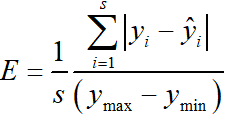
7. Показываем, как происходит и с помощью какого метода, настройка параметра размытости. В том числе графически, откладывая по оси абсцисс значения параметра размытости, а по оси ординат значение критерия
8. Показываем полученную оценку графически, откладывая по оси абсцисс номер точки, а по оси ординат выборочные значения и полученные по оценке регрессии
9. Проверяем работу оценки на тестовой выборке
10. Проводим исследования: изменяя форму ядерной функции и изменяя объем обучающей выборки. Проводим анализ, делаем выводы
11. Даем рекомендации по использованию данной оценки

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from sklearn.model_selection import KFold

In [2]:
np.random.seed(42)

In [3]:
n_train = 300

# 1. Чистые данные (разные масштабы)
x1_clean = np.random.uniform(-1, 1, size=n_train)
x2_clean = np.random.uniform(np.pi/2, np.pi, size=n_train)
x3_clean = np.random.uniform(0, 2000, size=n_train)
X_clean = np.column_stack((x1_clean, x2_clean, x3_clean))

# Истинная зависимость
y_clean = (2 * np.sin(x1_clean) * np.cos(x2_clean)
           + np.log1p(x3_clean)
           + 0.5 * x1_clean * (x3_clean / 1000) - 1)

# 2. Добавляем шум к X и y
noise_x1 = np.random.normal(0, 0.1, size=n_train)
noise_x2 = np.random.normal(0, 0.1, size=n_train)
noise_x3 = np.random.normal(0, 50, size=n_train)
noise_y = np.random.normal(0, 0.2, size=n_train)

X_noisy = np.column_stack((x1_clean + noise_x1, x2_clean + noise_x2, x3_clean + noise_x3))
y_noisy = y_clean + noise_y

In [4]:
def plot_3d(X, y, title):
    fig = go.Figure(data=[go.Scatter3d(
        x=X[:, 0], y=X[:, 1], z=X[:, 2],
        mode='markers',
        marker=dict(size=4, color=y, colorscale='Viridis', colorbar=dict(title="y"), opacity=0.8)
    )])
    fig.update_layout(title=title, scene=dict(xaxis_title='x1', yaxis_title='x2', zaxis_title='x3'), height=600, width=800)
    fig.show()

plot_3d(X_clean, y_clean, "Чистые данные: зависимость y от трех переменных")
plot_3d(X_noisy, y_noisy, "Зашумленные данные: зависимость y от трех переменных")

In [5]:
def nw_multi(X_train, y_train, X_test, h_vec, kernel='gaussian'):
    """Оценка Надарая-Ватсона с разными h для каждого признака."""
    # Матрица нормированных расстояний: (m_тест, n_обуч, d_признаки)
    U = (X_train[None, :, :] - X_test[:, None, :]) / h_vec[None, None, :]

    if kernel == 'gaussian':
        K = np.exp(-0.5 * U**2)
    elif kernel == 'epanechnikov':
        K = np.where(np.abs(U) <= 1, 0.75 * (1 - U**2), 0)

    W = np.prod(K, axis=2)  # Перемножаем ядра по всем признакам
    num = W @ y_train
    den = W.sum(axis=1)
    
    # Защита от деления на ноль
    return np.where(den > 0, num / np.where(den > 0, den, 1), y_train.mean())

def calculate_mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def calculate_E(y_true, y_pred):
    # Формула из задания
    s = len(y_true)
    return (1 / s) * (np.sum(np.abs(y_true - y_pred)) / (np.max(y_true) - np.min(y_true)))

In [10]:
def cv_mse(X, y, h_vec, n_folds=5):
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
    mse = 0.0
    for tr, va in kf.split(X):
        y_pred = nw_multi(X[tr], y[tr], X[va], h_vec)
        mse += np.mean((y[va] - y_pred)**2)
    return mse / n_folds

def select_h(X, y):
    h = X.std(axis=0) * len(X)**(-1/5) # Начальное приближение (правило Сильвермана)
    for _ in range(3):
        for j in range(3):
            grid = np.geomspace(h[j] / 3, h[j] * 3, 10)
            best_val, best_h = np.inf, h[j]
            for hj in grid:
                h_try = h.copy()
                h_try[j] = hj
                v = cv_mse(X, y, h_try)
                if v < best_val:
                    best_val, best_h = v, hj
            h[j] = best_h
    return h

# Находим оптимальные значения
h_opt = select_h(X_noisy, y_noisy)
print(f"Оптимальные параметры: h1={h_opt[0]:.4f}, h2={h_opt[1]:.4f}, h3={h_opt[2]:.2f}")

# === ПОСТРОЕНИЕ ТРЕХ ГРАФИКОВ ===

fig = make_subplots(
    rows=1, cols=3, 
    subplot_titles=(f"Влияние h1 на MSE (h2={h_opt[1]:.3f}, h3={h_opt[2]:.1f})", 
                    f"Влияние h2 на MSE (h1={h_opt[0]:.3f}, h3={h_opt[2]:.1f})", 
                    f"Влияние h3 на MSE (h1={h_opt[0]:.3f}, h2={h_opt[1]:.3f})")
)

# Перебираем j = 0 (h1), 1 (h2), 2 (h3)
for j in range(3):
    # Создаем сетку значений для текущего h_j (от оптимального в 5 раз меньше до в 5 раз больше)
    h_grid = np.geomspace(h_opt[j] / 5, h_opt[j] * 5, 15)
    mse_list = []
    
    for hj in h_grid:
        h_try = h_opt.copy()
        h_try[j] = hj
        mse_list.append(cv_mse(X_noisy, y_noisy, h_try))
        
    # Добавляем линию на график
    fig.add_trace(
        go.Scatter(x=h_grid, y=mse_list, mode='lines+markers', 
                   name=f'MSE для h{j+1}', line=dict(width=2)),
        row=1, col=j+1
    )
    
    # Добавляем вертикальную пунктирную линию (оптимум)
    fig.add_vline(
        x=h_opt[j], line_dash="dash", line_color="green", 
        annotation_text=f"Оптимум h{j+1}", row=1, col=j+1
    )
    
    # Настраиваем оси (ось X обязательно в логарифмическом масштабе!)
    fig.update_xaxes(type='log', title_text=f'h{j+1} (лог. шкала)', row=1, col=j+1)
    fig.update_yaxes(title_text='CV MSE' if j == 0 else '', row=1, col=j+1)

fig.update_layout(
    height=450, width=1300,
    title_text="Настройка параметров размытости: у каждого признака свой масштаб и свой минимум",
    showlegend=False
)
fig.show()

Оптимальные параметры: h1=0.2738, h2=0.2232, h3=61.24


In [7]:
y_pred_train = nw_multi(X_noisy, y_noisy, X_noisy, h_opt)

idx = np.arange(n_train)
fig = go.Figure()
fig.add_trace(go.Scatter(x=idx, y=y_clean, mode='lines', name='Истина', line=dict(color='blue', width=2)))
fig.add_trace(go.Scatter(x=idx, y=y_noisy, mode='markers', name='Зашумленные', marker=dict(color='gray', opacity=0.4, size=4)))
fig.add_trace(go.Scatter(x=idx, y=y_pred_train, mode='markers', name='Оценка NW', marker=dict(color='red', size=5, symbol='x')))

fig.update_layout(title="Сравнение по номеру точки", xaxis_title="Номер точки", yaxis_title="y", height=500)
fig.show()

In [8]:
n_test = 100
x1_t = np.random.uniform(-1, 1, size=n_test) + np.random.normal(0, 0.1, n_test)
x2_t = np.random.uniform(np.pi/2, np.pi, size=n_test) + np.random.normal(0, 0.1, n_test)
x3_t = np.random.uniform(0, 2000, size=n_test) + np.random.normal(0, 50, n_test)
X_test = np.column_stack((x1_t, x2_t, x3_t))

y_test_true = (2 * np.sin(x1_t) * np.cos(x2_t) + np.log1p(x3_t) + 0.5 * x1_t * (x3_t / 1000) - 1)
y_test = y_test_true + np.random.normal(0, 0.2, n_test)

# Прогноз на тесте
y_pred_test = nw_multi(X_noisy, y_noisy, X_test, h_opt)

print(f"ТЕСТ: MSE = {calculate_mse(y_test, y_pred_test):.4f}, E = {calculate_E(y_test, y_pred_test):.4f}")

# График Истина vs Прогноз
fig = go.Figure()
fig.add_trace(go.Scatter(x=y_test, y=y_pred_test, mode='markers', name='Прогноз на тесте', marker=dict(color='green', opacity=0.7, size=8)))
fig.add_trace(go.Scatter(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], mode='lines', name='Идеал', line=dict(color='red', dash='dash')))
fig.update_layout(title="Проверка на тестовой выборке", xaxis_title="Истинные значения", yaxis_title="Предсказанные значения")
fig.show()

ТЕСТ: MSE = 0.1338, E = 0.0366


In [9]:
# Исследование 1: Ядро Епанечникова
y_pred_epan = nw_multi(X_noisy, y_noisy, X_test, h_opt, kernel='epanechnikov')
print(f"Ядро Епанечникова: MSE = {calculate_mse(y_test, y_pred_epan):.4f}")

# Исследование 2: Малая выборка (N=50)
n_small = 50
X_small = X_noisy[:n_small]
y_small = y_noisy[:n_small]
y_pred_small = nw_multi(X_small, y_small, X_test, h_opt)
print(f"Малая выборка (N=50): MSE = {calculate_mse(y_test, y_pred_small):.4f}")

Ядро Епанечникова: MSE = 0.4752
Малая выборка (N=50): MSE = 0.3683
